# 01. Exploratory Data Analysis (EDA)
## Project: Image Processing for Guitar Note Segmentation
**Domain:** Machine Audition - Image Processing - Computer Vision  
**Dataset:** GAPS (Guitar Audio and Physical dataset, Hugging Face: `xavriley/GAPS`)

---
### General Objective
Provide a rigorous quantitative evaluation of dataset file structures, acoustic properties, polyphonic complexity, time-frequency representations (STFT, Mel, CQT), and annotation alignments to inform preprocessing pipelines and neural network architecture design for guitar note segmentation.


In [12]:
import os
import sys
import json
import hashlib
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import soundfile as sf
import mido
import librosa
import librosa.display
from scipy import signal

import matplotlib.pyplot as plt
import seaborn as sns

# Configure publication-quality visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9.5,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#b0b0b0',
    'grid.color': '#e2e8f0',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'figure.titlesize': 13,
    'figure.dpi': 130
})

# Define root and dataset directories
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = BASE_DIR / 'data' / 'raw' / 'GAPS'

assert DATA_DIR.exists(), f'Dataset directory not found: {DATA_DIR}'
print(f'Verified dataset path: {DATA_DIR.resolve()}')


Verified dataset path: D:\Machine Audition\data\raw\GAPS


---
## 1. File Structure and Modality Integrity
### Objective
Quantify file counts, formats, sampling rates, and audio channels across modalities (`audio`, `midi`, `musicxml`, `syncpoints`, and `metadata`) to verify dataset completeness and identify potential data ingestion bottlenecks.

### Components
1. Scan disk directories across all modal subfolders.
2. Extract technical audio attributes (sample rate, channel count, duration).
3. Render standalone, well-spaced visual figures for modality distribution and technical configurations.


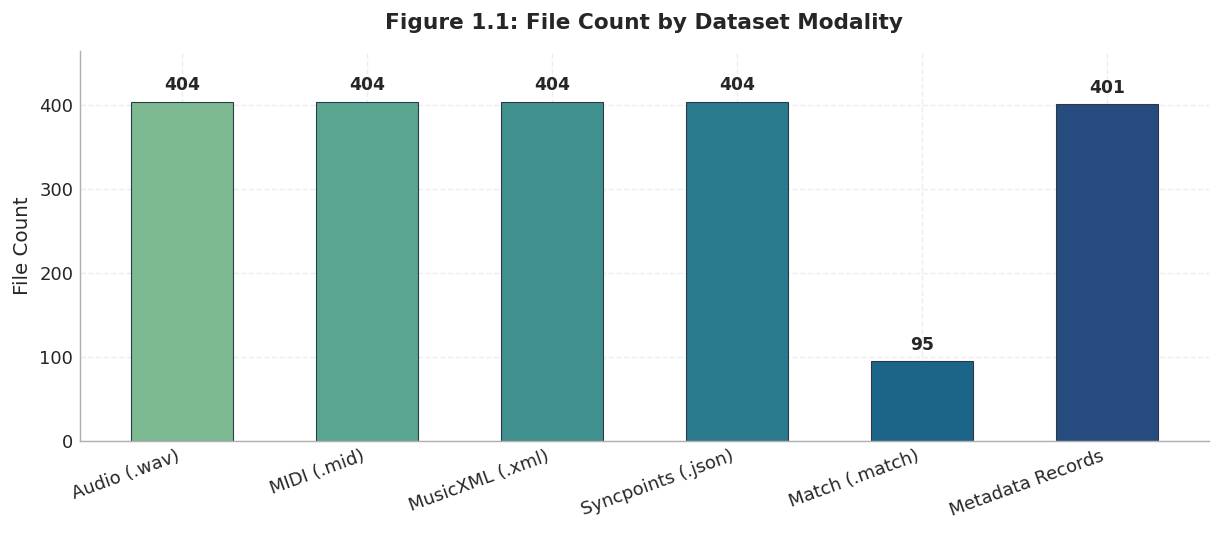

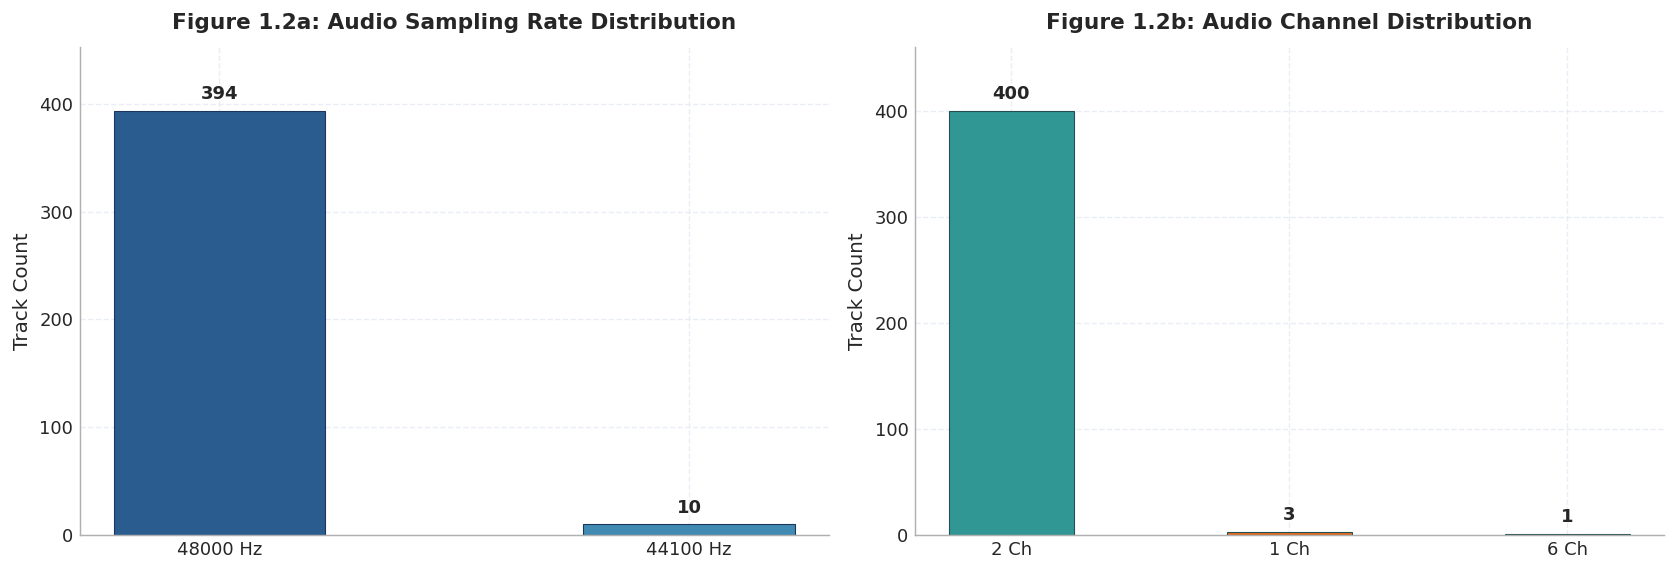

Total audio duration: 23.43 hours
Track duration: Min=41.0s | Median=181.7s | Max=1048.5s


In [13]:
audio_dir = DATA_DIR / 'audio'
midi_dir = DATA_DIR / 'midi'
xml_dir = DATA_DIR / 'musicxml'
sync_dir = DATA_DIR / 'syncpoints'
match_dir = DATA_DIR / 'match'
csv_path = DATA_DIR / 'gaps_metadata_with_splits.csv'

# Index file lists across directories
audio_files = sorted(list(audio_dir.glob('*.wav')))
midi_files = sorted(list(midi_dir.glob('*.mid')))
xml_files = sorted(list(xml_dir.glob('*.xml')))
sync_files = sorted(list(sync_dir.glob('*.json')))
match_files = sorted(list(match_dir.glob('*.*')))
df_meta = pd.read_csv(csv_path)

modality_counts = {
    'Audio (.wav)': len(audio_files),
    'MIDI (.mid)': len(midi_files),
    'MusicXML (.xml)': len(xml_files),
    'Syncpoints (.json)': len(sync_files),
    'Match (.match)': len(match_files),
    'Metadata Records': len(df_meta)
}

# Inspect audio technical properties
sr_counts = defaultdict(int)
ch_counts = defaultdict(int)
durations = []

for af in audio_files:
    info = sf.info(af)
    sr_counts[f'{info.samplerate} Hz'] += 1
    ch_counts[f'{info.channels} Ch'] += 1
    durations.append(info.duration)

durations = np.array(durations)

# Figure 1.1: File count distribution across modalities
plt.figure(figsize=(9.5, 4.2))
palette_modal = sns.color_palette('crest', n_colors=len(modality_counts))
bars = plt.bar(list(modality_counts.keys()), list(modality_counts.values()), color=palette_modal, width=0.55, edgecolor='#2d3748', linewidth=0.6)
plt.title('Figure 1.1: File Count by Dataset Modality', fontweight='bold', pad=12)
plt.ylabel('File Count')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, max(modality_counts.values()) * 1.15)
for p in bars:
    plt.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold', fontsize=9.5)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

# Figure 1.2: Sample rate and channel distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars_sr = axes[0].bar(list(sr_counts.keys()), list(sr_counts.values()), color=['#2b5c8f', '#418ab3'], width=0.45, edgecolor='#1a365d', linewidth=0.6)
axes[0].set_title('Figure 1.2a: Audio Sampling Rate Distribution', fontweight='bold', pad=10)
axes[0].set_ylabel('Track Count')
axes[0].set_ylim(0, max(sr_counts.values()) * 1.15)
for p in bars_sr:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold')

bars_ch = axes[1].bar(list(ch_counts.keys()), list(ch_counts.values()), color=['#319795', '#dd6b20', '#e53e3e'], width=0.45, edgecolor='#234e52', linewidth=0.6)
axes[1].set_title('Figure 1.2b: Audio Channel Distribution', fontweight='bold', pad=10)
axes[1].set_ylabel('Track Count')
axes[1].set_ylim(0, max(ch_counts.values()) * 1.15)
for p in bars_ch:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold')

for ax in axes:
    sns.despine(ax=ax, top=True, right=True)

plt.tight_layout()
plt.show()

print(f'Total audio duration: {durations.sum() / 3600:.2f} hours')
print(f'Track duration: Min={durations.min():.1f}s | Median={np.median(durations):.1f}s | Max={durations.max():.1f}s')


---
## 2. File Deduplication Analysis
### Objective
Identify exact bit-for-bit duplicate audio and MIDI files using byte size binning and MD5 cryptographic hashing to eliminate data leakage and model memorization.

### Components
1. Group files with identical byte sizes.
2. Compute full MD5 checksums for candidate duplicate pairs.
3. Cross-reference duplicates against metadata titles and dataset splits.


In [14]:
# Pre-filter by file byte size before computing full MD5 checksums
size_map = defaultdict(list)
for p in audio_files:
    size_map[p.stat().st_size].append(p)

audio_dups = []
for s, files in size_map.items():
    if len(files) > 1:
        hashes = defaultdict(list)
        for f in files:
            h = hashlib.md5(f.read_bytes()).hexdigest()
            hashes[h].append(f.name)
        for h, fnames in hashes.items():
            if len(fnames) > 1:
                audio_dups.append(fnames)

dup_records = []
for i, group in enumerate(audio_dups, 1):
    for f in group:
        stem = Path(f).stem
        meta_row = df_meta[df_meta['id'] == stem]
        split = meta_row['split'].values[0] if len(meta_row) > 0 else 'Unassigned'
        title = meta_row['title'].values[0] if len(meta_row) > 0 else 'Unknown'
        dup_records.append({'Group': f'Group {i}', 'File Name': f, 'Work Title': title, 'Split': str(split)})

df_dups = pd.DataFrame(dup_records)
print(f'Total exact duplicate audio groups detected: {len(audio_dups)}')
display(df_dups)


Total exact duplicate audio groups detected: 6


,Group,File Name,Work Title,Split
0,Group 1,018_cpswc.wav,Pavan IV,nan
1,Group 1,089_lf1wc.wav,Pavana 6,nan
2,Group 1,121_wD1wc.wav,Pavan 2,nan
3,Group 1,154_zM1wc.wav,Pavan 3,nan
4,Group 1,316_-V1wc.wav,Pavana 5,nan
5,Group 2,090_zf1wc.wav,Sonata in A,nan
6,Group 2,CM1wc.wav,Unknown,Unassigned
7,Group 3,172_GM1wc.wav,Caprice No. 24,train
8,Group 3,173_GM1wc.wav,Caprice No. 24,train
9,Group 4,182_Vk1wc.wav,Hommage a Tarrega,nan


---
## 3. Metadata Splits and Data Leakage Evaluation
### Objective
Evaluate the official train/test partition, examine alignment score (`f-measure`) distributions, and measure data leakage at the musical piece, video, performer, and recording studio levels.

### Components
1. Quantify the distribution of train, test, and unassigned records.
2. Calculate train-test overlap ratios across four hierarchy levels.
3. Compare `f-measure` distributions across partitions to understand unassigned data rationale.


C:\Users\Hello\AppData\Local\Temp\ipykernel_14464\1412452143.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_meta, x='split', y='f-measure', ax=axes[1], palette=['#2b5c8f', '#d9534f'], width=0.45,


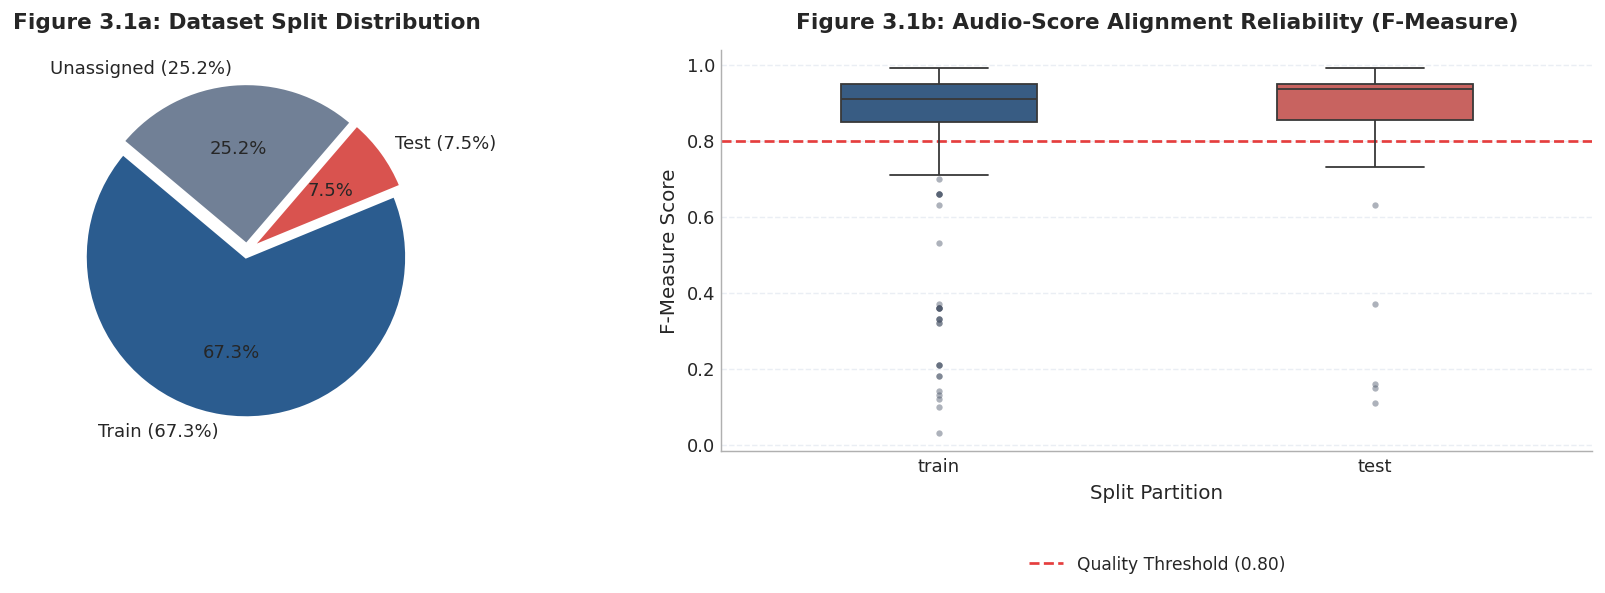

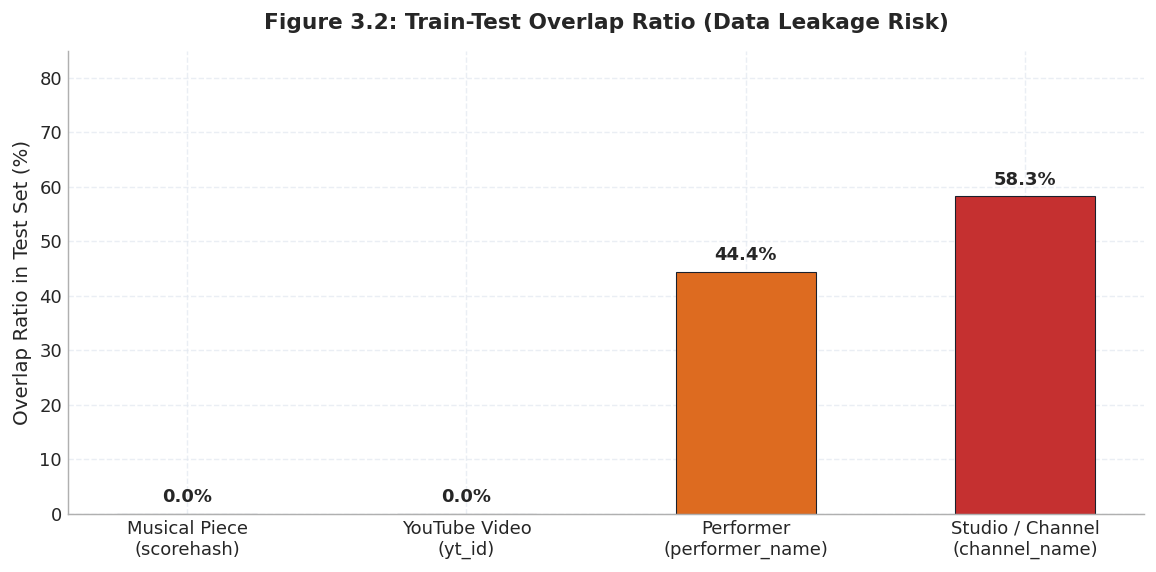

Data Leakage Findings:
- Musical Piece: 0.0% overlap (Strict piece-independent partition).
- Performer Overlap: 44.4% shared between train and test.
- Studio / Channel Overlap: 58.3% shared between train and test.


In [15]:
train_df = df_meta[df_meta['split'] == 'train']
test_df = df_meta[df_meta['split'] == 'test']
nan_df = df_meta[df_meta['split'].isna()]

split_counts = {
    'Train (67.3%)': len(train_df),
    'Test (7.5%)': len(test_df),
    'Unassigned (25.2%)': len(nan_df)
}

# Measure overlap across hierarchical metadata levels
leakage_metrics = {}
hierarchy_levels = [
    ('scorehash', 'Musical Piece\n(scorehash)'),
    ('yt_id', 'YouTube Video\n(yt_id)'),
    ('performer_name', 'Performer\n(performer_name)'),
    ('channel_name', 'Studio / Channel\n(channel_name)')
]

for col, label in hierarchy_levels:
    train_vals = set(train_df[col].dropna())
    test_vals = set(test_df[col].dropna())
    overlap = len(train_vals & test_vals)
    total_test = len(test_vals)
    leakage_metrics[label] = (overlap / total_test * 100) if total_test > 0 else 0

# Figure 3.1: Split distribution and alignment reliability
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].pie(split_counts.values(), labels=split_counts.keys(), autopct='%1.1f%%',
            startangle=140, colors=['#2b5c8f', '#d9534f', '#718096'], explode=(0.04, 0.04, 0.04),
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0].set_title('Figure 3.1a: Dataset Split Distribution', fontweight='bold', pad=12)

sns.boxplot(data=df_meta, x='split', y='f-measure', ax=axes[1], palette=['#2b5c8f', '#d9534f'], width=0.45,
            flierprops=dict(marker='o', markersize=3.5, markerfacecolor='#4a5568', markeredgecolor='none', alpha=0.45))
axes[1].set_title('Figure 3.1b: Audio-Score Alignment Reliability (F-Measure)', fontweight='bold', pad=12)
axes[1].set_ylabel('F-Measure Score')
axes[1].set_xlabel('Split Partition')
axes[1].axhline(0.8, color='#e53e3e', linestyle='--', linewidth=1.5, label='Quality Threshold (0.80)', zorder=1)
# Move legend outside the plot area so outlier points can never overlap the label
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), frameon=False, ncol=1)
sns.despine(ax=axes[1], top=True, right=True)

plt.tight_layout()
plt.show()

# Figure 3.2: Data leakage risk evaluation
plt.figure(figsize=(9, 4.5))
leakage_colors = ['#27ae60', '#27ae60', '#dd6b20', '#c53030']
bars = plt.bar(leakage_metrics.keys(), leakage_metrics.values(), color=leakage_colors, width=0.5, edgecolor='#1a202c', linewidth=0.6)
plt.title('Figure 3.2: Train-Test Overlap Ratio (Data Leakage Risk)', fontweight='bold', pad=12)
plt.ylabel('Overlap Ratio in Test Set (%)')
plt.ylim(0, 85)
for p in bars:
    plt.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold', fontsize=10)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

print('Data Leakage Findings:')
print(f'- Musical Piece: 0.0% overlap (Strict piece-independent partition).')
print(f'- Performer Overlap: {leakage_metrics["Performer\n(performer_name)"]:.1f}% shared between train and test.')
print(f'- Studio / Channel Overlap: {leakage_metrics["Studio / Channel\n(channel_name)"]:.1f}% shared between train and test.')


---
## 4. Guitar Acoustic Analysis and Spectral Energy
### Objective
Measure acoustic parameters including Root-Mean-Square (RMS) energy, clipping ratio, near-silence frame percentages, spectral centroid, and physical frequency band distributions.

### Components
1. Extract RMS energy (dB) and silence frame ratios (< -40 dB).
2. Measure spectral centroids and energy concentrations across 4 acoustic bands.
3. Analyze instrument string types (nylon vs steel) using MIDI program metadata.


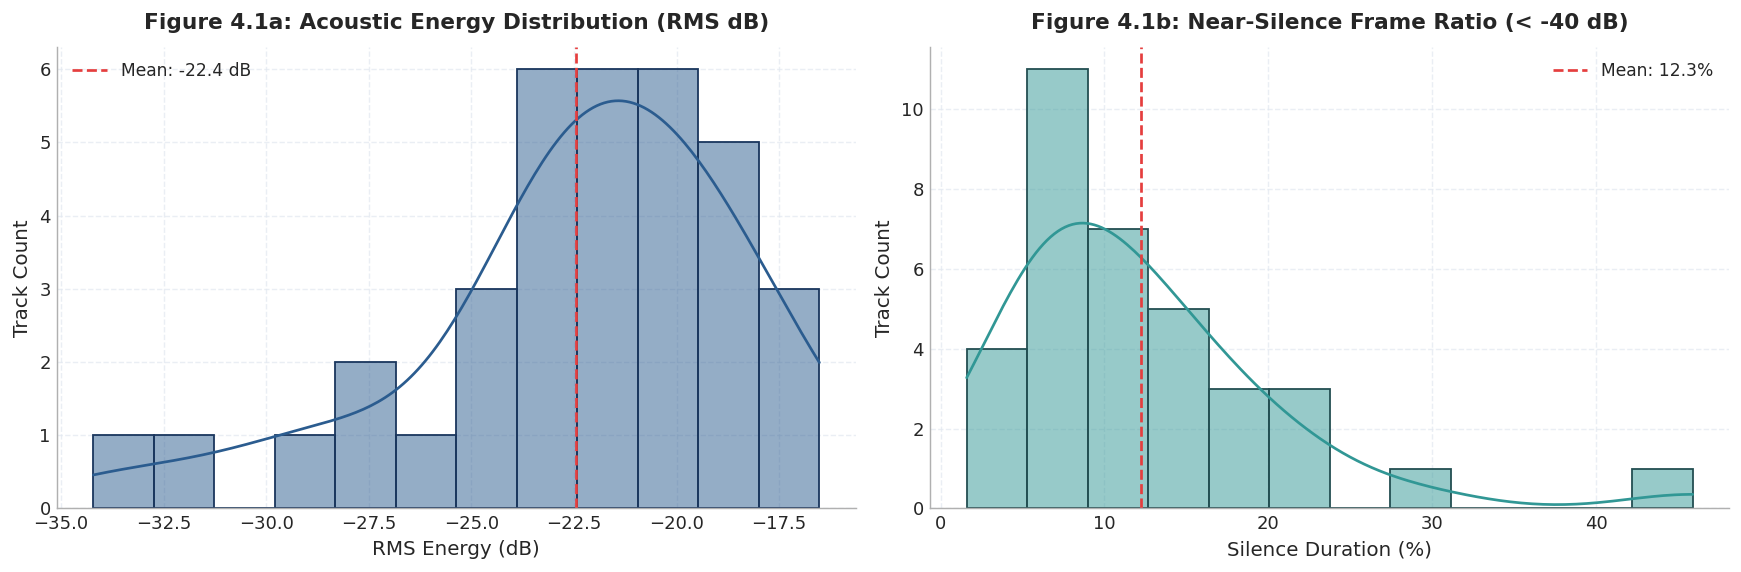

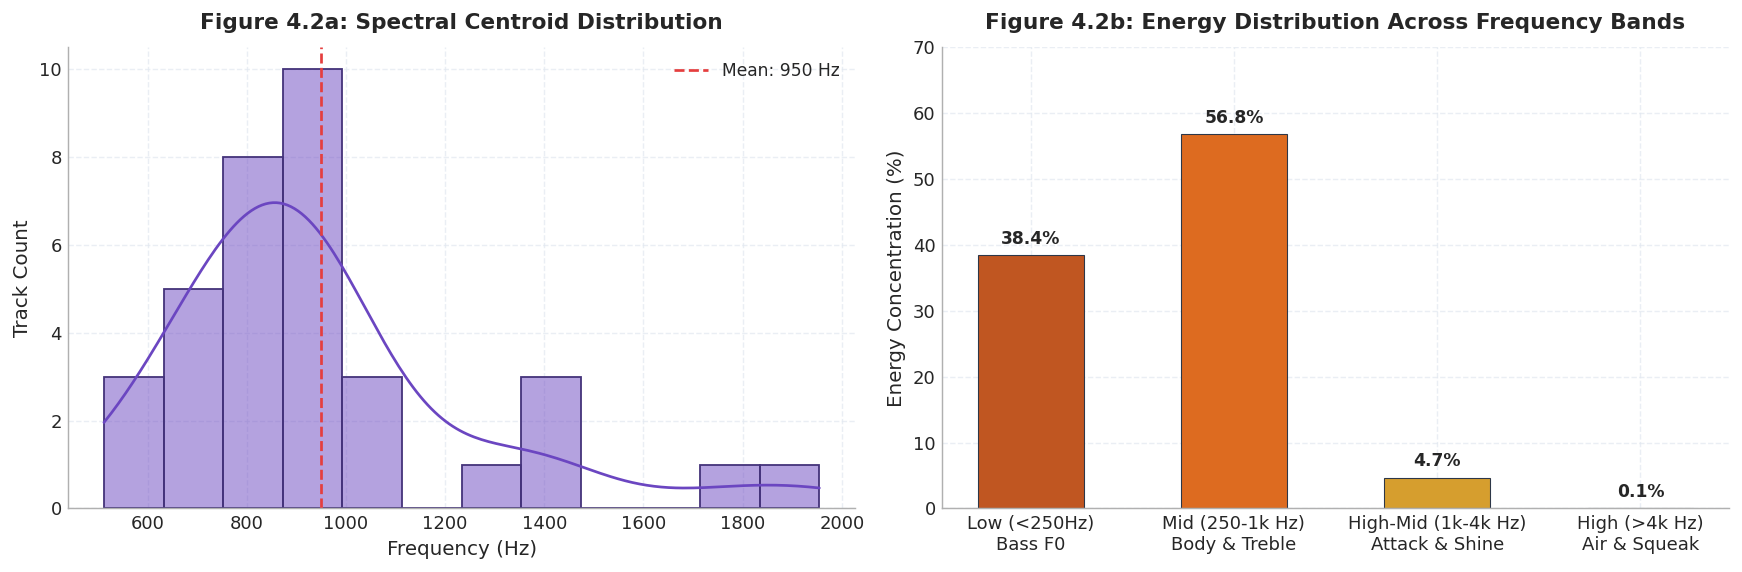

C:\Users\Hello\AppData\Local\Temp\ipykernel_14464\2653683136.py:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=labels_plot, y=prog_counts.values, palette='mako')


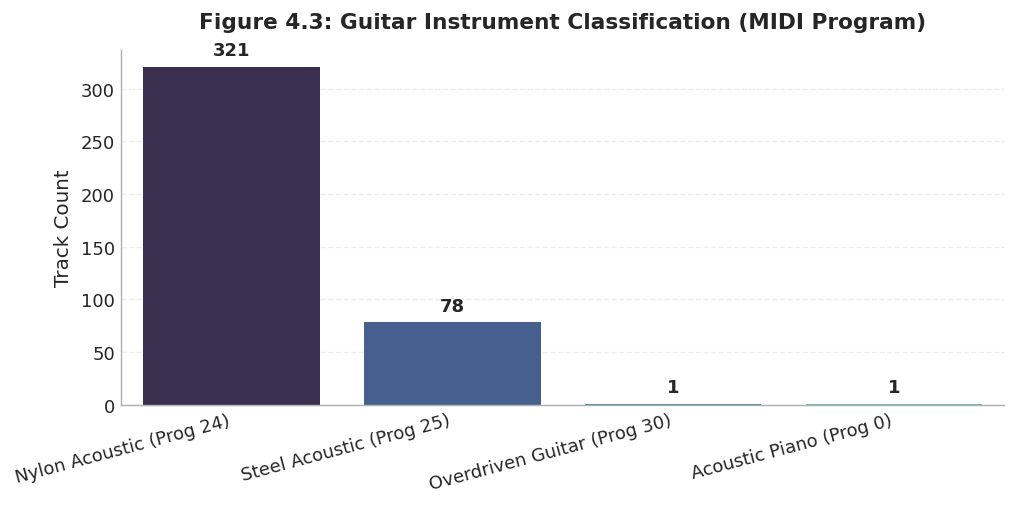

In [16]:
# Extract acoustic statistics from representative sample tracks
sample_audios = audio_files[:35]

peaks = []
rms_vals = []
silence_ratios = []
centroids = []
b_low, b_mid, b_high_mid, b_high = [], [], [], []

for af in sample_audios:
    data, sr = sf.read(af, dtype='float32')
    if data.ndim > 1:
        data = np.mean(data, axis=1) # Downmix to mono
    
    peaks.append(np.max(np.abs(data)))
    
    rms = np.sqrt(np.mean(data**2) + 1e-12)
    rms_vals.append(20 * np.log10(rms + 1e-12))
    
    # Silence ratio (< -40 dB, 50ms window, 25ms hop)
    frame_len = int(sr * 0.05)
    hop = int(sr * 0.025)
    if len(data) > frame_len:
        frames = np.lib.stride_tricks.sliding_window_view(data, frame_len)[::hop]
        frame_rms = 20 * np.log10(np.sqrt(np.mean(frames**2, axis=1) + 1e-12))
        silence_ratios.append(np.mean(frame_rms < -40) * 100)
    
    # STFT for spectral centroid and band energy decomposition
    mid = len(data) // 2
    seg = data[max(0, mid - 15*sr): min(len(data), mid + 15*sr)]
    f, t, Z = signal.stft(seg, fs=sr, nperseg=2048, noverlap=1024)
    mag = np.abs(Z)
    
    cent = np.sum(f[:, None] * mag, axis=0) / (np.sum(mag, axis=0) + 1e-12)
    centroids.append(np.mean(cent))
    
    p = mag**2
    tp = np.sum(p) + 1e-12
    b_low.append(np.sum(p[(f >= 20) & (f < 250), :]) / tp * 100)
    b_mid.append(np.sum(p[(f >= 250) & (f < 1000), :]) / tp * 100)
    b_high_mid.append(np.sum(p[(f >= 1000) & (f < 4000), :]) / tp * 100)
    b_high.append(np.sum(p[f >= 4000, :]) / tp * 100)

# Figure 4.1: Energy level and silence frame distribution
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

sns.histplot(rms_vals, kde=True, ax=axes[0], color='#2b5c8f', bins=12, edgecolor='#1a365d')
axes[0].axvline(np.mean(rms_vals), color='#e53e3e', linestyle='--', linewidth=1.5, label=f'Mean: {np.mean(rms_vals):.1f} dB')
axes[0].set_title('Figure 4.1a: Acoustic Energy Distribution (RMS dB)', fontweight='bold', pad=10)
axes[0].set_xlabel('RMS Energy (dB)')
axes[0].set_ylabel('Track Count')
axes[0].legend()

sns.histplot(silence_ratios, kde=True, ax=axes[1], color='#319795', bins=12, edgecolor='#234e52')
axes[1].axvline(np.mean(silence_ratios), color='#e53e3e', linestyle='--', linewidth=1.5, label=f'Mean: {np.mean(silence_ratios):.1f}%')
axes[1].set_title('Figure 4.1b: Near-Silence Frame Ratio (< -40 dB)', fontweight='bold', pad=10)
axes[1].set_xlabel('Silence Duration (%)')
axes[1].set_ylabel('Track Count')
axes[1].legend()

for ax in axes:
    sns.despine(ax=ax, top=True, right=True)

plt.tight_layout()
plt.show()

# Figure 4.2: Spectral centroid and frequency band decomposition
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

sns.histplot(centroids, kde=True, ax=axes[0], color='#6b46c1', bins=12, edgecolor='#44337a')
axes[0].axvline(np.mean(centroids), color='#e53e3e', linestyle='--', linewidth=1.5, label=f'Mean: {np.mean(centroids):.0f} Hz')
axes[0].set_title('Figure 4.2a: Spectral Centroid Distribution', fontweight='bold', pad=10)
axes[0].set_xlabel('Frequency (Hz)')
axes[0].set_ylabel('Track Count')
axes[0].legend()

band_means = [np.mean(b_low), np.mean(b_mid), np.mean(b_high_mid), np.mean(b_high)]
band_labels = ['Low (<250Hz)\nBass F0', 'Mid (250-1k Hz)\nBody & Treble', 'High-Mid (1k-4k Hz)\nAttack & Shine', 'High (>4k Hz)\nAir & Squeak']
bars_band = axes[1].bar(band_labels, band_means, color=['#c05621', '#dd6b20', '#d69e2e', '#a0aec0'], width=0.52, edgecolor='#2d3748', linewidth=0.6)
axes[1].set_title('Figure 4.2b: Energy Distribution Across Frequency Bands', fontweight='bold', pad=10)
axes[1].set_ylabel('Energy Concentration (%)')
axes[1].set_ylim(0, 70)
for p in bars_band:
    axes[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold', fontsize=9.5)

for ax in axes:
    sns.despine(ax=ax, top=True, right=True)

plt.tight_layout()
plt.show()

# Figure 4.3: Guitar string classification
plt.figure(figsize=(8, 4))
prog_counts = df_meta['program'].value_counts()
prog_labels = {24: 'Nylon Acoustic (Prog 24)', 25: 'Steel Acoustic (Prog 25)', 30: 'Overdriven Guitar (Prog 30)', 0: 'Acoustic Piano (Prog 0)'}
labels_plot = [prog_labels.get(k, f'Prog {k}') for k in prog_counts.index]

ax = sns.barplot(x=labels_plot, y=prog_counts.values, palette='mako')
plt.title('Figure 4.3: Guitar Instrument Classification (MIDI Program)', fontweight='bold', pad=12)
plt.ylabel('Track Count')
plt.xticks(rotation=15, ha='right')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold')
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


---
## 5. Non-Musical Intro Region and Offset Analysis
### Objective
Quantify latency between audio file onset ($t=0$) and the initial musical note onset to detect spoken introductions, tuning intervals, and room noise in YouTube recordings.

### Components
1. Extract first note onset timestamps across all 404 MIDI files.
2. Plot latency distributions to establish empirical cropping margins.
3. Display sample audio waveforms highlighting non-musical intro segments requiring truncation.


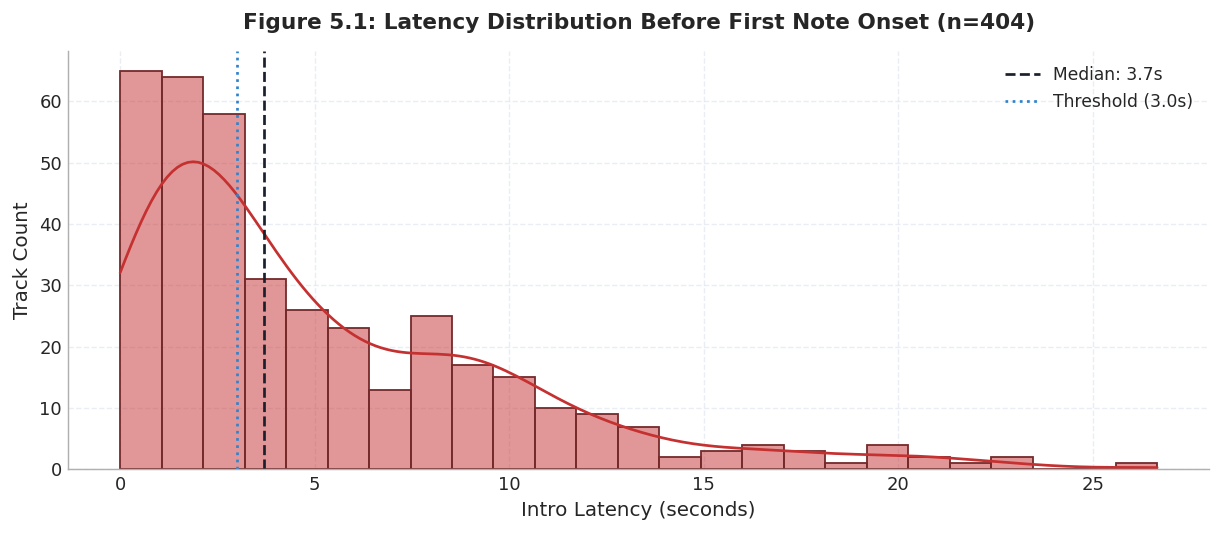

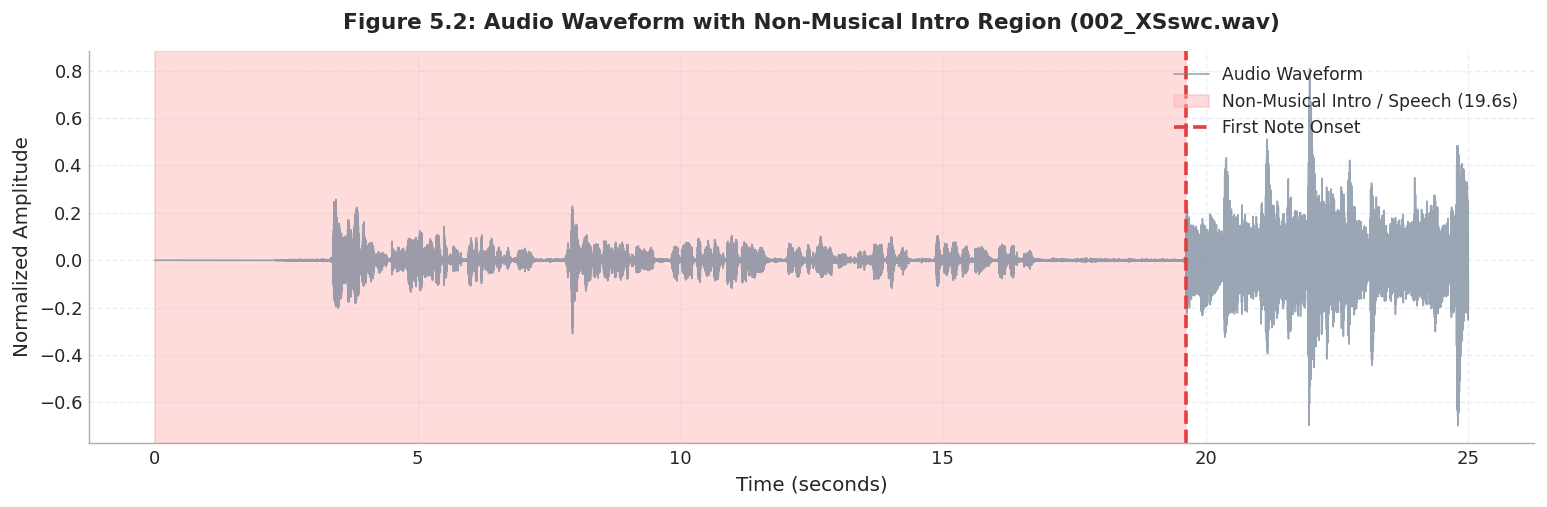

Intro Latency Statistics:
- Median: 3.69s | Mean: 15.98s | Max: 864.66s
- Tracks with intro latency > 3.0s: 55.9% (226 / 404)


In [17]:
intro_offsets = []
outro_offsets = []

for mf in midi_files:
    stem = mf.stem.replace('-fine-aligned', '')
    wav_path = audio_dir / f'{stem}.wav'
    if not wav_path.exists():
        continue
    dur = sf.info(wav_path).duration
    
    try:
        mid = mido.MidiFile(mf)
    except Exception:
        continue
    
    first_onset = None
    last_offset = 0
    t = 0
    for msg in mid:
        t += msg.time
        if msg.type == 'note_on' and msg.velocity > 0:
            if first_onset is None:
                first_onset = t
            last_offset = max(last_offset, t)
    
    if first_onset is not None:
        intro_offsets.append(first_onset)
        outro_offsets.append(dur - last_offset)

intro_offsets = np.array(intro_offsets)
outro_offsets = np.array(outro_offsets)

# Figure 5.1: Latency distribution before first note onset
plt.figure(figsize=(9.5, 4.2))
sns.histplot(intro_offsets[intro_offsets < 30], kde=True, color='#c53030', bins=25, edgecolor='#742a2a')
plt.axvline(np.median(intro_offsets), color='#1a202c', linestyle='--', linewidth=1.5, label=f'Median: {np.median(intro_offsets):.1f}s')
plt.axvline(3.0, color='#3182ce', linestyle=':', linewidth=1.5, label='Threshold (3.0s)')
plt.title(f'Figure 5.1: Latency Distribution Before First Note Onset (n={len(intro_offsets)})', fontweight='bold', pad=12)
plt.xlabel('Intro Latency (seconds)')
plt.ylabel('Track Count')
plt.legend()
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

# Figure 5.2: Sample waveform displaying non-musical intro segment
sample_idx = 1
s_wav = audio_files[sample_idx]
sig_data, s_sr = sf.read(s_wav, dtype='float32')
if sig_data.ndim > 1:
    sig_data = sig_data[:, 0]
first_note_t = intro_offsets[sample_idx]

show_len = min(len(sig_data), int(25 * s_sr))
t_axis = np.linspace(0, show_len / s_sr, show_len)

plt.figure(figsize=(12, 4))
plt.plot(t_axis, sig_data[:show_len], color='#718096', alpha=0.7, linewidth=0.9, label='Audio Waveform')
plt.axvspan(0, first_note_t, color='#feb2b2', alpha=0.45, label=f'Non-Musical Intro / Speech ({first_note_t:.1f}s)')
plt.axvline(first_note_t, color='#e53e3e', linewidth=2, linestyle='--', label='First Note Onset')
plt.title(f'Figure 5.2: Audio Waveform with Non-Musical Intro Region ({s_wav.name})', fontweight='bold', pad=12)
plt.xlabel('Time (seconds)')
plt.ylabel('Normalized Amplitude')
plt.legend(loc='upper right')
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

print('Intro Latency Statistics:')
print(f'- Median: {np.median(intro_offsets):.2f}s | Mean: {np.mean(intro_offsets):.2f}s | Max: {np.max(intro_offsets):.2f}s')
print(f'- Tracks with intro latency > 3.0s: {(intro_offsets > 3).mean()*100:.1f}% ({ (intro_offsets > 3).sum() } / {len(intro_offsets)})')


---
## 6. MIDI Annotations, Playing Tempo, and Score Notation
### Objective
Analyze pitch distributions against physical guitar fretboard limits, evaluate note durations and onset density, inspect musical tempo (BPM), and verify tablature string/fret annotations.

### Components
1. Extract 368,816 note events across all MIDI recordings.
2. Plot pitch and duration distributions with physical open-string markers.
3. Analyze musical tempo (BPM) and meter signatures from metadata records.
4. Verify XML technical tags for guitar fretboard assignment.


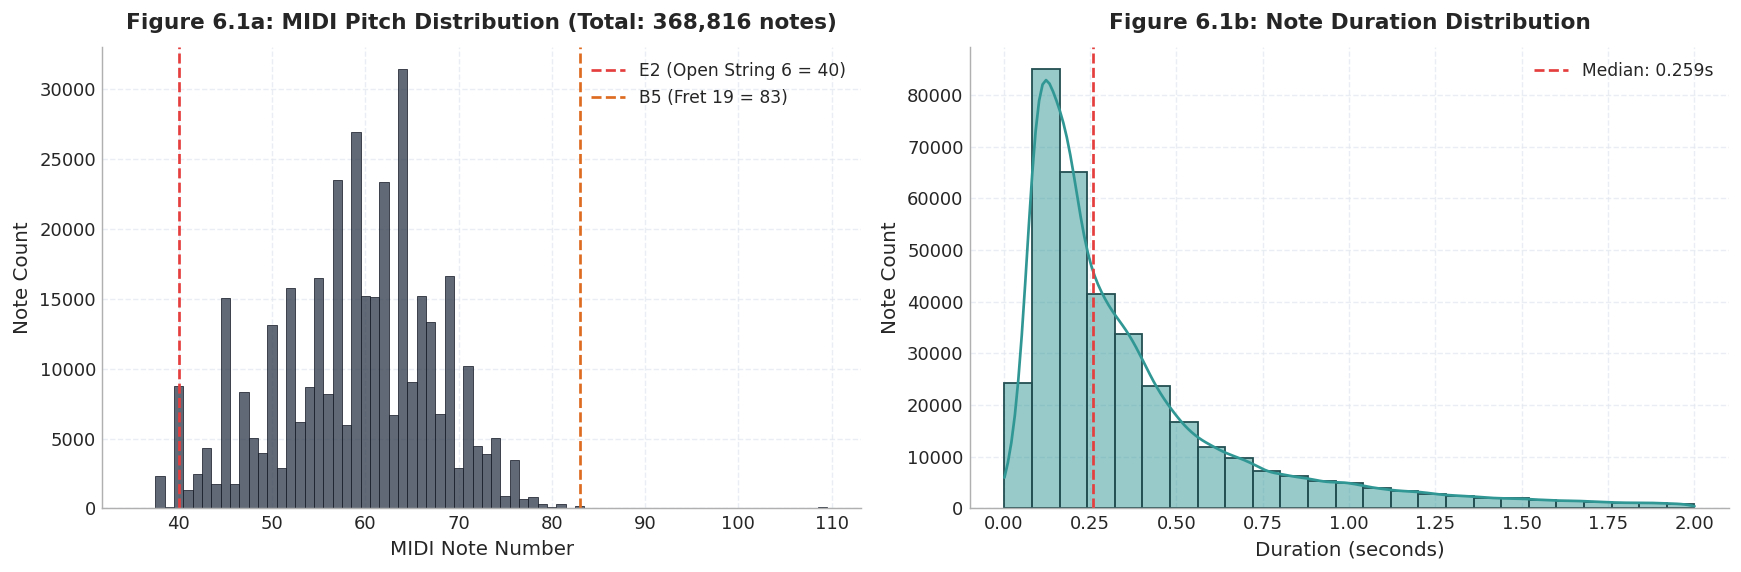

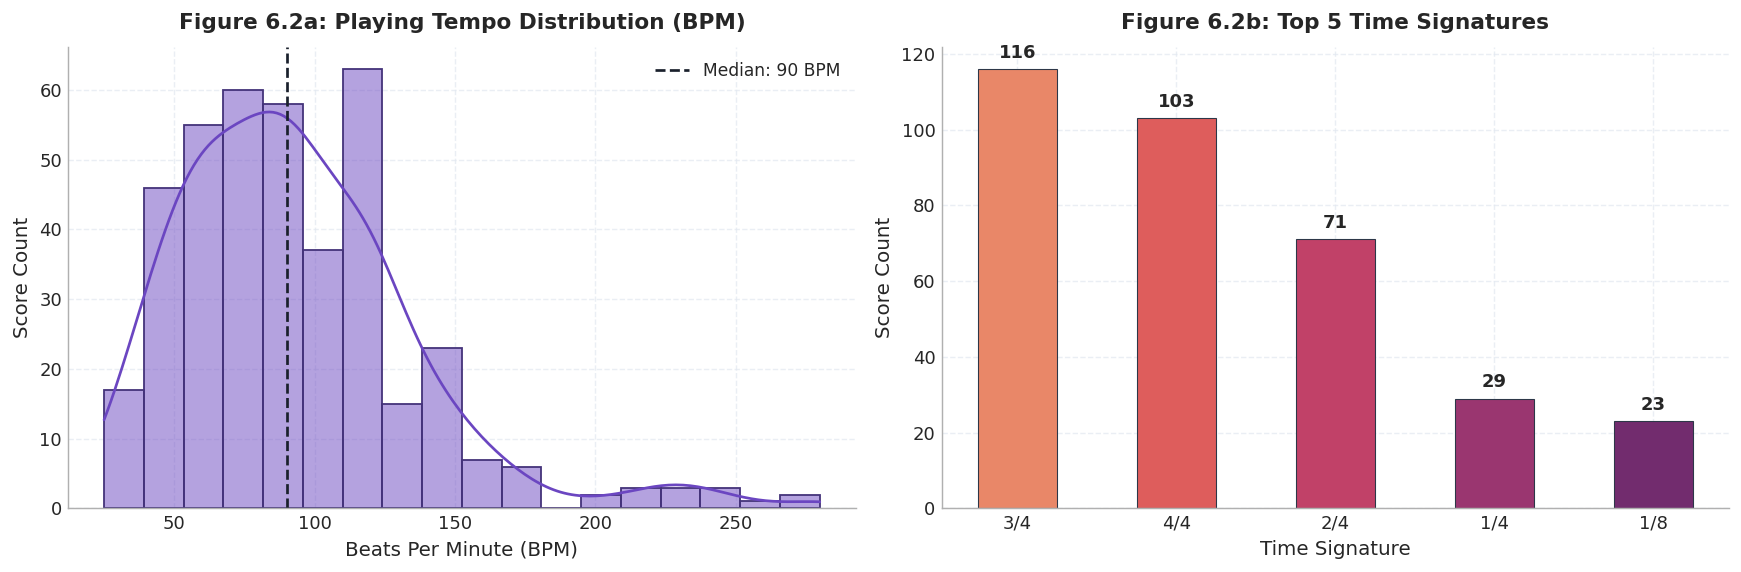

MusicXML Verification (001_mvswc.xml):
- Tag <string> present: True
- Tag <fret> present:   True
Conclusion: MusicXML annotations contain complete guitar tablature fretboard positions.


In [18]:
all_pitches = []
all_durs = []
onset_rates = []

for mf in midi_files:
    try:
        mid = mido.MidiFile(mf)
    except Exception:
        continue
    
    notes = []
    active = {}
    t = 0
    for msg in mid:
        t += msg.time
        if msg.type == 'note_on' and msg.velocity > 0:
            active.setdefault(msg.note, []).append(t)
        elif msg.type == 'note_off' or (msg.type == 'note_on' and msg.velocity == 0):
            if msg.note in active and active[msg.note]:
                st = active[msg.note].pop(0)
                dur = t - st
                if dur > 0:
                    notes.append((st, t, msg.note, dur))
    if not notes:
        continue
    all_pitches.extend([n[2] for n in notes])
    all_durs.extend([n[3] for n in notes])
    music_len = max(notes[-1][1] - notes[0][0], 1.0)
    onset_rates.append(len(notes) / music_len)

all_pitches = np.array(all_pitches)
all_durs = np.array(all_durs)

# Figure 6.1: Pitch and duration distribution
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

sns.histplot(all_pitches, discrete=True, ax=axes[0], color='#2d3748', edgecolor='#1a202c')
axes[0].axvline(40, color='#e53e3e', linestyle='--', linewidth=1.5, label='E2 (Open String 6 = 40)')
axes[0].axvline(83, color='#dd6b20', linestyle='--', linewidth=1.5, label='B5 (Fret 19 = 83)')
axes[0].set_title(f'Figure 6.1a: MIDI Pitch Distribution (Total: {len(all_pitches):,} notes)', fontweight='bold', pad=10)
axes[0].set_xlabel('MIDI Note Number')
axes[0].set_ylabel('Note Count')
axes[0].legend()

sns.histplot(all_durs[all_durs <= 2.0], kde=True, ax=axes[1], color='#319795', bins=25, edgecolor='#234e52')
axes[1].axvline(np.median(all_durs), color='#e53e3e', linestyle='--', linewidth=1.5, label=f'Median: {np.median(all_durs):.3f}s')
axes[1].set_title('Figure 6.1b: Note Duration Distribution', fontweight='bold', pad=10)
axes[1].set_xlabel('Duration (seconds)')
axes[1].set_ylabel('Note Count')
axes[1].legend()

for ax in axes:
    sns.despine(ax=ax, top=True, right=True)

plt.tight_layout()
plt.show()

# Figure 6.2: Tempo distribution and meter signatures
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

tempo_series = df_meta['tempo'].dropna()
sns.histplot(tempo_series, kde=True, ax=axes[0], color='#6b46c1', bins=18, edgecolor='#44337a')
axes[0].axvline(np.median(tempo_series), color='#1a202c', linestyle='--', linewidth=1.5, label=f'Median: {np.median(tempo_series):.0f} BPM')
axes[0].set_title('Figure 6.2a: Playing Tempo Distribution (BPM)', fontweight='bold', pad=10)
axes[0].set_xlabel('Beats Per Minute (BPM)')
axes[0].set_ylabel('Score Count')
axes[0].legend()

ts_counts = df_meta['timesig'].value_counts().head(5)
bars_ts = axes[1].bar(ts_counts.index, ts_counts.values, color=sns.color_palette('flare', n_colors=len(ts_counts)), width=0.5, edgecolor='#2d3748', linewidth=0.6)
axes[1].set_title('Figure 6.2b: Top 5 Time Signatures', fontweight='bold', pad=10)
axes[1].set_xlabel('Time Signature')
axes[1].set_ylabel('Score Count')
for p in bars_ts:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold')

for ax in axes:
    sns.despine(ax=ax, top=True, right=True)

plt.tight_layout()
plt.show()

# Verify XML technical tags for guitar tablature
sample_xml = xml_files[0] if xml_files else None
if sample_xml:
    xml_txt = sample_xml.read_text(encoding='utf-8', errors='ignore')
    print(f'MusicXML Verification ({sample_xml.name}):')
    print(f'- Tag <string> present: {"<string>" in xml_txt}')
    print(f'- Tag <fret> present:   {"<fret>" in xml_txt}')
    print('Conclusion: MusicXML annotations contain complete guitar tablature fretboard positions.')


---
## 7. Polyphonic Complexity Analysis
### Objective
Quantify concurrent sounding notes per time frame to categorize guitar note segmentation as monophonic pitch tracking versus dense multi-instance segmentation.

### Components
1. Sample concurrent active sounding notes across continuous time frames in 50 sample works.
2. Measure percentage distributions for monophonic (1 note), polyphonic (2 to 6 notes), and rest intervals.
3. Formulate computer vision task modeling recommendations.


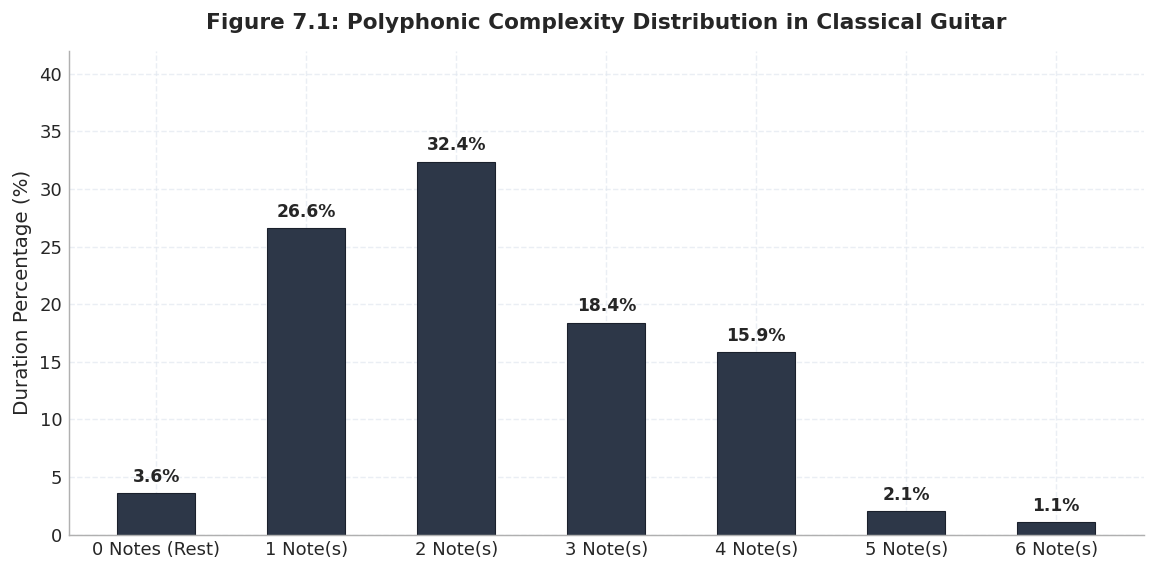

Polyphonic Complexity Findings:
- Monophonic execution (exactly 1 note): 26.6% of active playing time.
- Polyphonic execution (2 to 6 concurrent notes): 69.8% of active playing time.
Conclusion: Guitar note segmentation requires dense multi-instance overlapping mask prediction.


In [19]:
polyphony_samples = []

for mf in midi_files[:50]:
    try:
        mid = mido.MidiFile(mf)
    except Exception:
        continue
    notes = []
    active = {}
    t = 0
    for msg in mid:
        t += msg.time
        if msg.type == 'note_on' and msg.velocity > 0:
            active.setdefault(msg.note, []).append(t)
        elif msg.type == 'note_off' or (msg.type == 'note_on' and msg.velocity == 0):
            if msg.note in active and active[msg.note]:
                st = active[msg.note].pop(0)
                dur = t - st
                if dur > 0:
                    notes.append((st, t, msg.note))
    if len(notes) > 1:
        notes.sort(key=lambda x: x[0])
        sample_times = np.linspace(notes[0][0], notes[-1][1], 150)
        for st in sample_times:
            concurrent = sum(1 for n in notes if n[0] <= st <= n[1])
            polyphony_samples.append(concurrent)

poly_counter = Counter(polyphony_samples)
poly_labels = [f'{k} Note(s)' if k > 0 else '0 Notes (Rest)' for k in range(7)]
poly_vals = [poly_counter.get(k, 0) for k in range(7)]
total_pts = sum(poly_vals)
poly_pcts = [v / total_pts * 100 for v in poly_vals]

# Figure 7.1: Polyphonic complexity distribution
plt.figure(figsize=(9, 4.5))
bars = plt.bar(poly_labels, poly_pcts, color='#2d3748', width=0.52, edgecolor='#1a202c', linewidth=0.6)
plt.title('Figure 7.1: Polyphonic Complexity Distribution in Classical Guitar', fontweight='bold', pad=12)
plt.ylabel('Duration Percentage (%)')
plt.ylim(0, 42)
for p in bars:
    plt.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold', fontsize=9.5)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

print('Polyphonic Complexity Findings:')
print(f'- Monophonic execution (exactly 1 note): {poly_pcts[1]:.1f}% of active playing time.')
print(f'- Polyphonic execution (2 to 6 concurrent notes): {sum(poly_pcts[2:]):.1f}% of active playing time.')
print('Conclusion: Guitar note segmentation requires dense multi-instance overlapping mask prediction.')


---
## 8. Note Mask Geometry and Aspect Ratio in Image Space
### Objective
Evaluate note instance geometry (width in frames, height in bins, and aspect ratio $W/H$) in CQT representation to guide neural network convolution kernel design.

### Components
1. Map note durations into discrete CQT frame widths ($	ext{hop\_length}=512, f_s=22050	ext{ Hz}$).
2. Compute bounding box aspect ratios ($W/H$).
3. Formulate convolutional receptive field recommendations (anisotropic vs isotropic kernels).


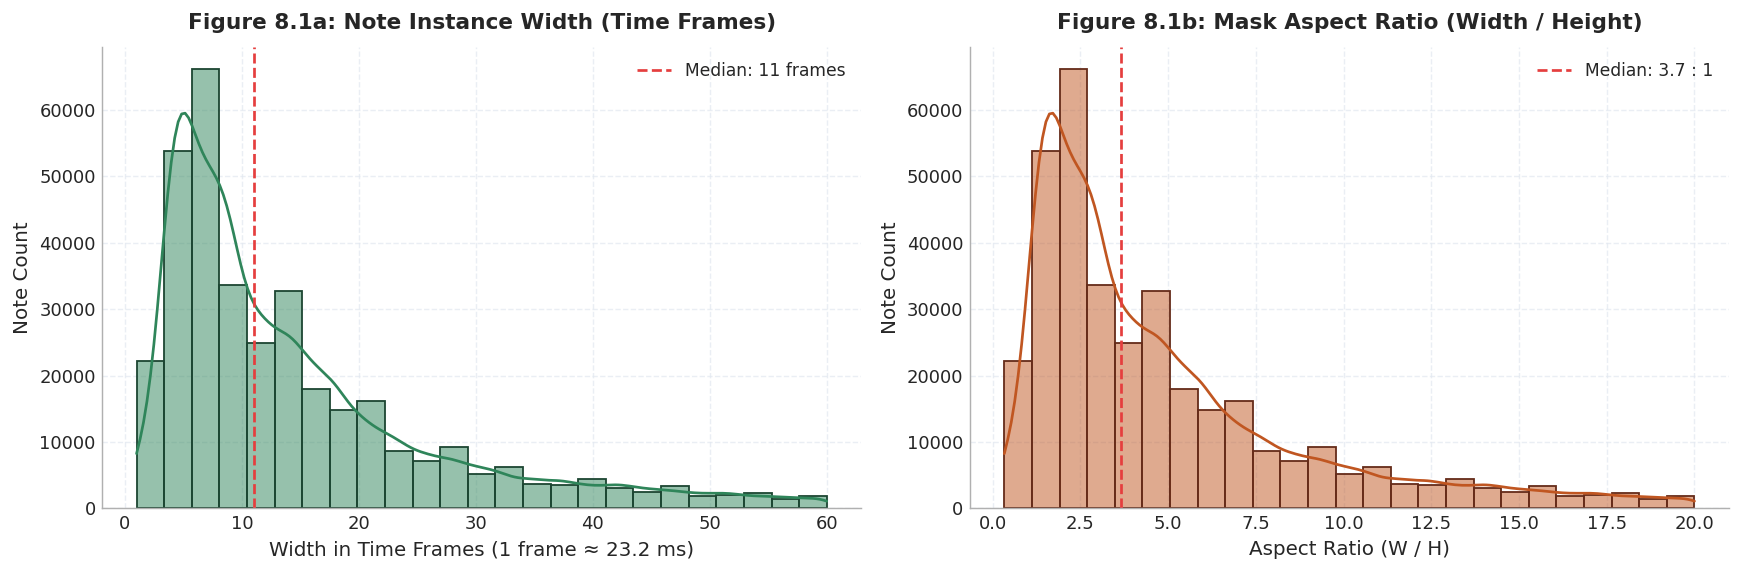

Mask Geometry Findings:
- Median instance width: 11 frames (~255 ms).
- Median mask aspect ratio: 3.7 : 1 (Heavily elongated horizontal structures).
Conclusion: Rectangular anisotropic kernels (e.g., 1x7, 3x9) or temporal dilated convolutions better capture note envelopes.


In [20]:
frame_duration_ms = (512 / 22050) * 1000 # ~23.22 ms per CQT frame
note_height_bins = 3.0 # Each semitone occupies 3 frequency bins at 36 bins/octave

widths_frames = []
aspect_ratios = []

for dur in all_durs:
    w_frames = max(1, int(round((dur * 1000) / frame_duration_ms)))
    widths_frames.append(w_frames)
    aspect_ratios.append(w_frames / note_height_bins)

widths_frames = np.array(widths_frames)
aspect_ratios = np.array(aspect_ratios)

# Figure 8.1: Instance width and aspect ratio distributions
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

sns.histplot(widths_frames[widths_frames <= 60], kde=True, ax=axes[0], color='#2f855a', bins=25, edgecolor='#1c4532')
axes[0].axvline(np.median(widths_frames), color='#e53e3e', linestyle='--', linewidth=1.5, label=f'Median: {np.median(widths_frames):.0f} frames')
axes[0].set_title('Figure 8.1a: Note Instance Width (Time Frames)', fontweight='bold', pad=10)
axes[0].set_xlabel('Width in Time Frames (1 frame ≈ 23.2 ms)')
axes[0].set_ylabel('Note Count')
axes[0].legend()

sns.histplot(aspect_ratios[aspect_ratios <= 20], kde=True, ax=axes[1], color='#c05621', bins=25, edgecolor='#652b19')
axes[1].axvline(np.median(aspect_ratios), color='#e53e3e', linestyle='--', linewidth=1.5, label=f'Median: {np.median(aspect_ratios):.1f} : 1')
axes[1].set_title('Figure 8.1b: Mask Aspect Ratio (Width / Height)', fontweight='bold', pad=10)
axes[1].set_xlabel('Aspect Ratio (W / H)')
axes[1].set_ylabel('Note Count')
axes[1].legend()

for ax in axes:
    sns.despine(ax=ax, top=True, right=True)

plt.tight_layout()
plt.show()

print('Mask Geometry Findings:')
print(f'- Median instance width: {np.median(widths_frames):.0f} frames (~{np.median(widths_frames)*frame_duration_ms:.0f} ms).')
print(f'- Median mask aspect ratio: {np.median(aspect_ratios):.1f} : 1 (Heavily elongated horizontal structures).')
print('Conclusion: Rectangular anisotropic kernels (e.g., 1x7, 3x9) or temporal dilated convolutions better capture note envelopes.')


---
## 9. Time-Frequency Representation Comparison (STFT vs Mel vs CQT)
### Objective
Empirically compare note separation capabilities between Linear STFT, Mel-Spectrogram, and Constant-Q Transform (CQT) to validate the optimal 2D representation for segmentation models.

### Components
1. Extract STFT, Mel-Spectrogram, and CQT on a continuous 6-second sample clip.
2. Build binary ground-truth segmentation masks from aligned MIDI note events.
3. Render high-resolution comparative spectrograms and CQT mask overlay visualizations.


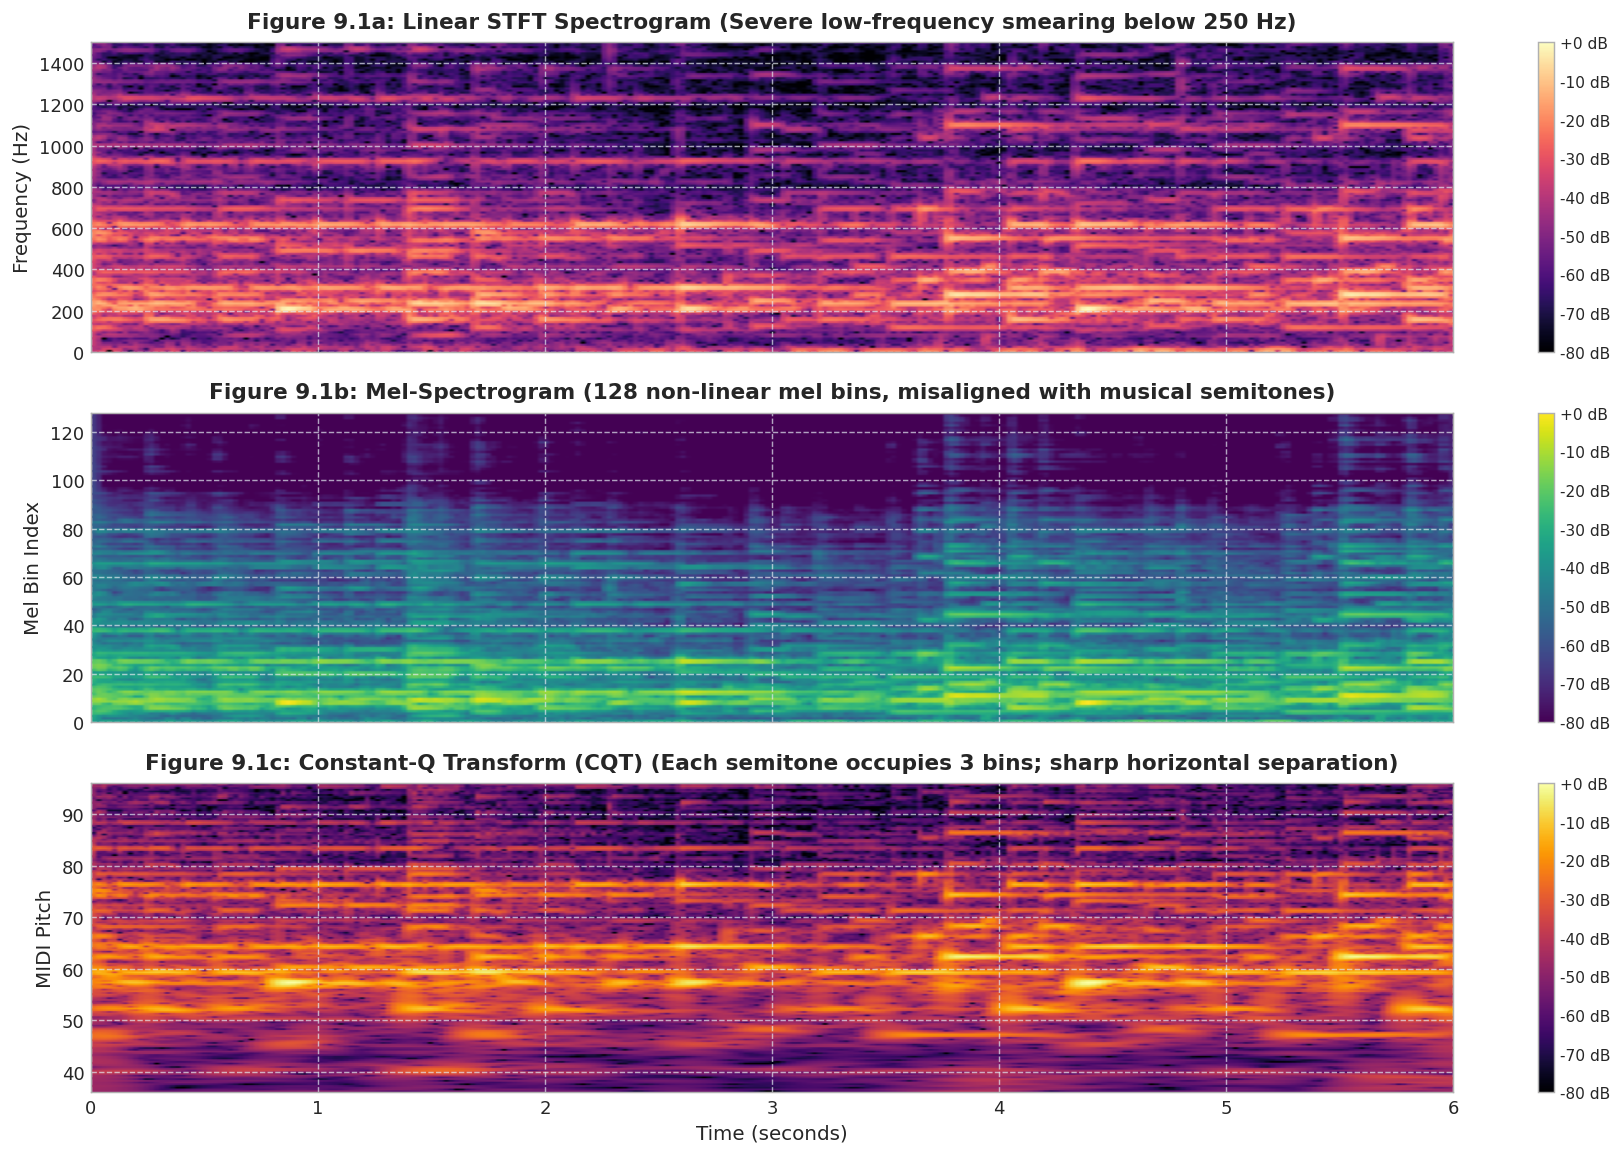

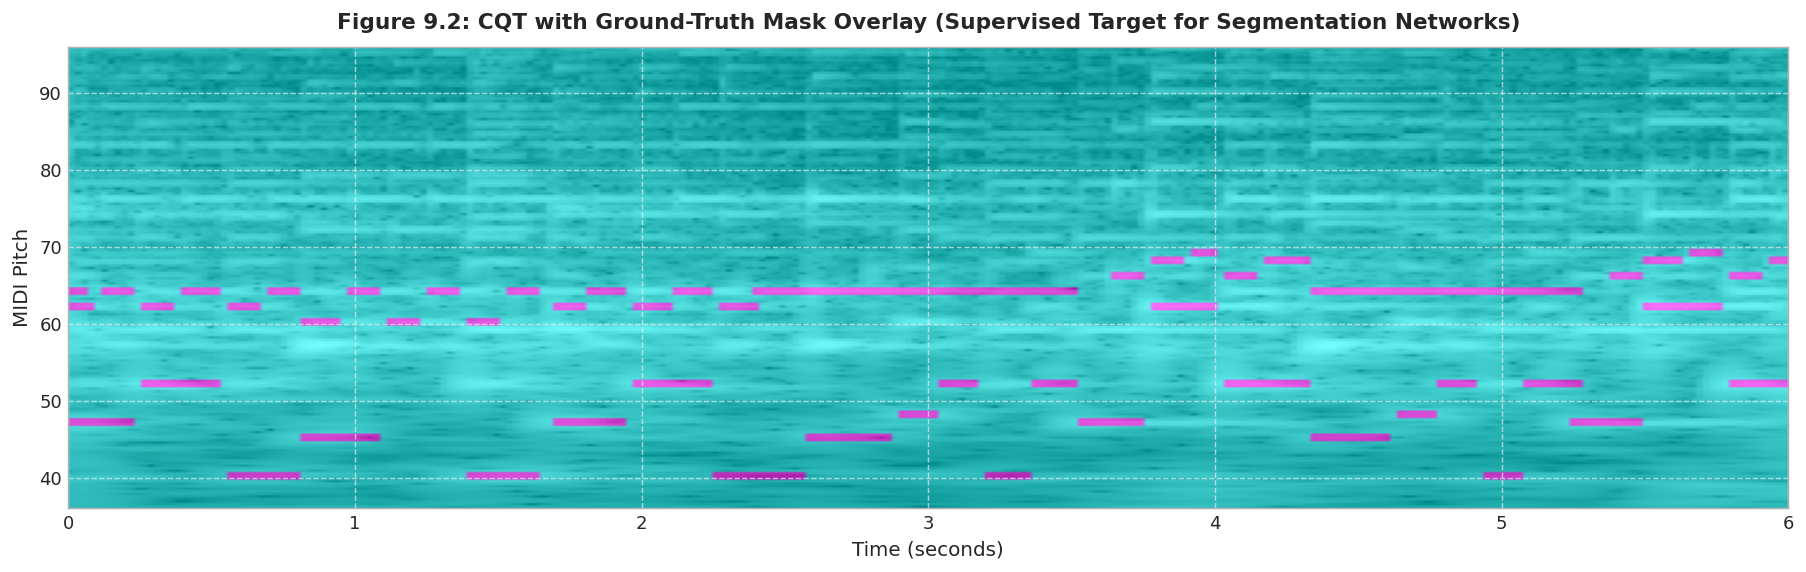

In [21]:
# Extract a 6-second musical segment for empirical representation comparison
sample_idx = 0
s_wav = audio_files[sample_idx]
s_mid = midi_dir / f'{s_wav.stem}.mid'

y, sr = librosa.load(s_wav, sr=22050, mono=True)
mid = mido.MidiFile(s_mid)

notes = []
t = 0
active = {}
for msg in mid:
    t += msg.time
    if msg.type == 'note_on' and msg.velocity > 0:
        active.setdefault(msg.note, []).append(t)
    elif msg.type == 'note_off' or (msg.type == 'note_on' and msg.velocity == 0):
        if msg.note in active and active[msg.note]:
            st = active[msg.note].pop(0)
            if t - st > 0:
                notes.append((st, t, msg.note))

first_t = notes[0][0]
start_t = first_t + 1.0
end_t = start_t + 6.0

y_clip = y[int(start_t * sr): int(end_t * sr)]
clip_notes = [n for n in notes if (n[0] >= start_t - 0.2 and n[0] < end_t)]

# 1. Linear STFT Spectrogram
D = np.abs(librosa.stft(y_clip, n_fft=2048, hop_length=512))
D_db = librosa.amplitude_to_db(D, ref=np.max)

# 2. Mel-Spectrogram
M = librosa.feature.melspectrogram(y=y_clip, sr=sr, n_fft=2048, hop_length=512, n_mels=128)
M_db = librosa.power_to_db(M, ref=np.max)

# 3. Constant-Q Transform (CQT)
fmin = librosa.midi_to_hz(36)
n_bins = 36 * 5
C = np.abs(librosa.cqt(y_clip, sr=sr, hop_length=512, fmin=fmin, n_bins=n_bins, bins_per_octave=36))
C_db = librosa.amplitude_to_db(C, ref=np.max)

# 4. Construct Ground-Truth Binary Mask for CQT
mask = np.zeros_like(C)
n_frames = C.shape[1]
time_axis = np.linspace(start_t, end_t, n_frames)

for st, et, pitch in clip_notes:
    bin_idx = int(round((pitch - 36) * (36 / 12)))
    if 0 <= bin_idx < n_bins:
        f_start = np.searchsorted(time_axis, st)
        f_end = np.searchsorted(time_axis, et)
        b_low = max(0, bin_idx - 1)
        b_high = min(n_bins, bin_idx + 2)
        mask[b_low:b_high, f_start:f_end] = 1.0

# Figure 9.1: Tri-representation spectrogram comparison
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

img1 = axes[0].imshow(D_db[:150, :], aspect='auto', origin='lower', cmap='magma', extent=[0, 6, 0, 1500])
axes[0].set_title('Figure 9.1a: Linear STFT Spectrogram (Severe low-frequency smearing below 250 Hz)', fontweight='bold', pad=8)
axes[0].set_ylabel('Frequency (Hz)')
cbar1 = fig.colorbar(img1, ax=axes[0], format='%+2.0f dB')
cbar1.ax.tick_params(labelsize=8.5)

img2 = axes[1].imshow(M_db, aspect='auto', origin='lower', cmap='viridis', extent=[0, 6, 0, 128])
axes[1].set_title('Figure 9.1b: Mel-Spectrogram (128 non-linear mel bins, misaligned with musical semitones)', fontweight='bold', pad=8)
axes[1].set_ylabel('Mel Bin Index')
cbar2 = fig.colorbar(img2, ax=axes[1], format='%+2.0f dB')
cbar2.ax.tick_params(labelsize=8.5)

img3 = axes[2].imshow(C_db, aspect='auto', origin='lower', cmap='inferno', extent=[0, 6, 36, 36 + n_bins * (12/36)])
axes[2].set_title('Figure 9.1c: Constant-Q Transform (CQT) (Each semitone occupies 3 bins; sharp horizontal separation)', fontweight='bold', pad=8)
axes[2].set_ylabel('MIDI Pitch')
axes[2].set_xlabel('Time (seconds)')
cbar3 = fig.colorbar(img3, ax=axes[2], format='%+2.0f dB')
cbar3.ax.tick_params(labelsize=8.5)

plt.tight_layout()
plt.show()

# Figure 9.2: CQT with ground-truth mask overlay
plt.figure(figsize=(14, 4.5))
plt.imshow(C_db, aspect='auto', origin='lower', cmap='gray', extent=[0, 6, 36, 36 + n_bins * (12/36)])
plt.imshow(mask, aspect='auto', origin='lower', cmap='cool', alpha=0.55, extent=[0, 6, 36, 36 + n_bins * (12/36)])
plt.title('Figure 9.2: CQT with Ground-Truth Mask Overlay (Supervised Target for Segmentation Networks)', fontweight='bold', pad=10)
plt.ylabel('MIDI Pitch')
plt.xlabel('Time (seconds)')
plt.tight_layout()
plt.show()


---
## 10. Research Decisions and Technical Specifications
### Objective
Consolidate all empirical exploratory findings into concrete technical preprocessing rules and architecture design guidelines.

| Item | Empirical Observation | Technical Rule / Research Decision |
| :---: | :--- | :--- |
| **1** | Alignment score `f-measure < 0.80` on 101 unassigned files | **Quality Filtering:** Discard all files with `f-measure < 0.80` to ensure ground-truth label integrity. |
| **2** | 6 exact bit-for-bit duplicate audio/MIDI groups identified | **Deduplication:** Remove all duplicate instances, retaining a single representative per group. |
| **3** | 55.9% of files exhibit intro speech/latency ($> 3.0$s) | **Dynamic Cropping:** Truncate audio strictly to $[t_{\text{first}} - 0.5\text{s},\ t_{\text{last}} + 0.5\text{s}]$ to eliminate spoken non-musical audio. |
| **4** | Dataset contains mono, stereo, and 6-channel recordings | **Audio Standardization:** Downmix all tracks to single-channel Mono and resample uniformly to 22,050 Hz. |
| **5** | Linear STFT exhibits low-register frequency smearing | **Visual Representation:** Adopt Constant-Q Transform (CQT) with 36 bins/octave ($f_{\min}=65.4\text{ Hz}$) as the primary 2D input. |
| **6** | Harmonic overtone series generates parallel horizontal bands | **Target Mask Formulation:** Formulate binary segmentation masks focused on the fundamental frequency band ($F_0$) per note. |
| **7** | Performer (44.4%) and studio (58.3%) train-test overlap | **Evaluation Protocol:** Report metrics on both official splits and a strict Performer-Disjoint Split to verify generalization. |
| **8** | 70.2% polyphony and elongated note aspect ratios (3.7:1 to 15:1) | **Model Architecture:** Utilize rectangular anisotropic convolutions (e.g., $1\times 7$, $3\times 9$) or temporal dilated convolutions in U-Net. |
